
## 🧠 From Biological to Artificial Neurons

Biological neurons form the inspiration for Artificial Neural Networks (ANNs). Each neuron receives electrical impulses through dendrites, integrates the signals in the soma (cell body), and fires an output via the axon if the input exceeds a threshold. Similarly, in ANNs, each artificial neuron sums weighted inputs and passes them through an activation function. Just as biological neurons form complex pathways in the brain, artificial neurons form layers in a neural network that can learn from data and simulate reasoning.

![Biological Neuron](./images/BioNeurons.png)



## ⚡ Neural Spikes vs. Compute Spikes

In the brain, neurons operate on an "all-or-nothing" basis: when a signal exceeds a threshold, an action potential fires, creating a spike in voltage over time. This is called the **integrate-and-fire** model. In deep learning, training large neural networks also generates spike-like behavior — but in CPU or GPU utilization! Spikes in electrical voltage in biological neurons mirror spikes in compute power during heavy processing. This analogy helps us appreciate how ANN training simulates (inspired by) the nervous system.

![Neuron Spikes](./images/NeuronSpikes.png)



## 🧮 Mathematical Model of an Artificial Neuron

![Deel Learning High-Level View](./images/DL_HighLevelView.png)

Each neuron computes a weighted sum of its inputs, adds a bias, and passes the result through an activation function:

$$
z = \sum_{j=0}^{m} w_j x_j = w_0 x_0 + w_1 x_1 + \cdots + w_m x_m
$$

Then, the output of the neuron is:

$$
\hat{y} = A(z)
$$

Where:
- $x_0$ is the bias input (typically set to 1)
- $w_j$ are the weights
- $A(z)$ is the activation function

This process models how neurons integrate input and "decide" whether to activate.




## 🧩 Activation Functions

Activation functions introduce non-linearity into neural networks, allowing them to model complex relationships.

### 🔹 Identity
$$
g(x) = x
$$
Linear output, rarely used alone.

### 🔹 Binary Step
$$
g(x) = 
\begin{cases}
0 & \text{if } x < 0 \\
1 & \text{if } x \geq 0
\end{cases}
$$
Used in early perceptrons.

### 🔹 Sigmoid
$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$
Smooth, output between 0 and 1. Good for probabilities.

### 🔹 Tanh
$$
\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$
Output between -1 and 1. Centered around zero.

### 🔹 ReLU (Rectified Linear Unit)
$$
\text{ReLU}(x) = \max(0, x)
$$
Default for hidden layers. Efficient and sparse.




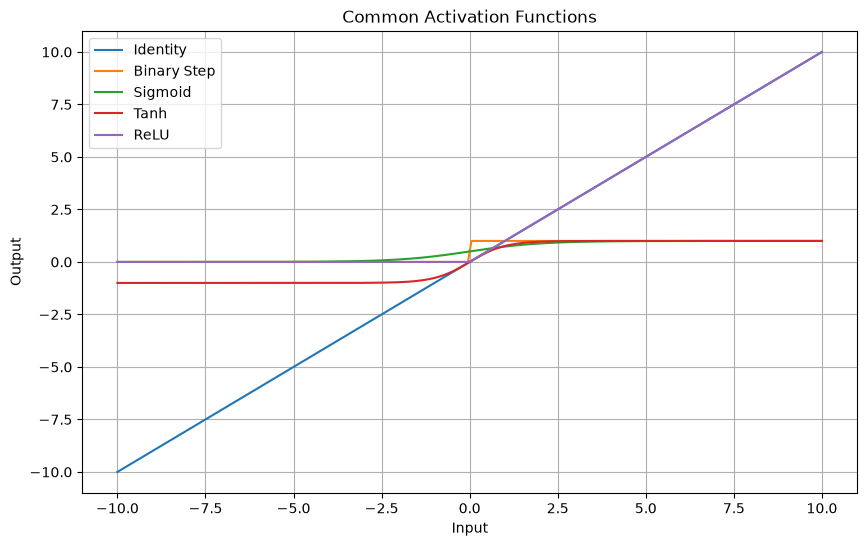

In [23]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 200)
identity = x
binary_step = np.where(x >= 0, 1, 0)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(10, 6))
plt.plot(x, identity, label='Identity')
plt.plot(x, binary_step, label='Binary Step')
plt.plot(x, sigmoid, label='Sigmoid')
plt.plot(x, tanh, label='Tanh')
plt.plot(x, relu, label='ReLU')
plt.title("Common Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.legend()
plt.show()


### 🧪 Interactive Experiment: TensorFlow Playground

Want to *experiment with neural networks* in real-time?

Click the link below to explore an interactive simulation using the **tanh activation function** and a **circular dataset**. Adjust parameters like learning rate, number of layers, and input features — and observe how the decision boundaries evolve.

👉 **[Launch the TensorFlow Playground Simulation](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.48465&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false)**

![Playground Preview](https://raw.githubusercontent.com/tensorflow/playground/master/images/playground.png)

🧠 Try changing the:
- Activation function (ReLU, tanh, sigmoid)
- Network shape (number of layers and neurons)
- Learning rate and batch size
- Input features (x, y, x², sin(x), etc.)

This is a powerful tool to build intuition about how neural networks **learn patterns**!



### 🗣️ Code Walkthrough Talking Points

- Each function maps input `x` to a transformed output — this controls how neurons activate.
- `Binary Step` is simple and fast but non-differentiable.
- `Sigmoid` and `Tanh` are smooth but suffer from vanishing gradients.
- `ReLU` is widely used due to efficiency and sparse activation.


## 🧠 Case Study: Are We Going to Canada's Wonderland?
We will now implement a simple artificial neural network using **PyTorch** to predict whether we’ll go to Canada's Wonderland based on three inputs:

- **X₁**: Weather — 1 if sunny, 0 if rainy
- **X₂**: Ticket queue — 1 if short, 0 if long
- **X₃**: Health — 1 if healthy, 0 if unwell

Each input has an associated **weight**, and the network uses a **bias** and a **sigmoid activation function** to generate a confidence value.

### 📊 Visual Summary: ANN Case Study – Are We Going to Canada's Wonderland?

Below is a visual walkthrough of the single-neuron prediction model:

| Slide 1 | Slide 2 |
|--------|--------|
| ![Slide 1](./images/ANN_1.png) | ![Slide 2](./images/ANN_2.png) |

| Slide 3 | Slide 4 |
|--------|--------|
| ![Slide 3](./images/ANN_3.png) | ![Slide 4](./images/ANN_4.png) |

| Slide 5 | Slide 6 |
|--------|--------|
| ![Slide 5](./images/ANN_5.png) | ![Slide 6](./images/ANN_6.png) |


### 🔢 Step 1: Prediction Function
We compute the neuron output $\hat{y}$ as:

$$
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{where} \quad z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b
$$

In our case:

- $x = [1, 0, 1]$
- $w = [5, 2, 4]$
- $b = -3$

In [24]:
import torch
import torch.nn as nn

# Inputs and weights
x = torch.tensor([1.0, 0.0, 1.0])
weights = torch.tensor([5.0, 2.0, 4.0])
bias = -3.0

# Linear combination
z = torch.dot(weights, x) + bias

# Sigmoid activation
sigmoid = torch.sigmoid(z)
print(f"z = {z.item():.2f}")
print(f"Predicted output (sigmoid) = {sigmoid.item():.4f}")

z = 6.00
Predicted output (sigmoid) = 0.9975


### 📈 Understanding the Output of Our Neuron

In the previous code cell, we computed the neuron's output using PyTorch:

```python
z = torch.dot(weights, x) + bias
sigmoid = torch.sigmoid(z)
```

#### 🔢 Here's how it breaks down:

Let’s plug in the numbers used in the slide (also shown in the code):

* Inputs: ( x = [1, 0, 1] )
* Weights: ( w = [5, 2, 4] )
* Bias: ( b = -3 )

The **linear combination** is computed as:

$$
\hat{y} = z = w_1x_1 + w_2x_2 + w_3x_3 + b = (1 \times 5) + (0 \times 2) + (1 \times 4) - 3 = 5 + 0 + 4 - 3 = 6
$$

Then, we pass this result through the **sigmoid activation function**:

$$
f(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^{-6}} \approx 0.9975
$$

This output is the **model’s confidence** (close to 1), which matches the slide’s annotation:

> “Therefore, we are going to Wonderland!”

🧠 **Interpretation**:

* Since $ \hat{y} = 6 $ and our threshold $ \tau = 3 $, and $ \hat{y} > \tau $, the neuron **fires**.
* The sigmoid output $ \approx 0.9975 $ tells us the model is **very confident** in its decision.

✅ Slide 2 in the table above, and the code are in **perfect agreement**.


### 💬 Talking Points
- We treat inputs like "sunny", "short queue", and "healthy" as binary features.
- The weighted sum (`z`) captures how favorable conditions are.
- Applying `sigmoid(z)` maps the decision to a probability.

### ❌ Step 2: Error Calculation
We compare the predicted value with the actual label:

$$
E = y - \hat{y}
$$

If the actual value is 1 (we should go), but our prediction is too low, we compute the error and update the weights.

In [25]:
y = torch.tensor(1.0)
error = y - sigmoid
print(f"Error = {error.item():.4f}")

Error = 0.0025


### 🧠 Talking Point: Why is the Error Different to that in the slides?

There’s an important distinction between **raw neuron output** $ \hat{y} $ and the **activated output** (confidence) $ f(z) $, which explains the discrepancy between:

* The error calculation in slide 4 in the table above is:
  $$
  E = y - \hat{y} = 1 - 6 = -5
  $$

* However, PyTorch code’s error calculation in the output above was:
  $$
  E = y - f(z) = 1 - 0.9975 = 0.0025
  $$

#### 🤔 What's happening?

* In **slides 4, 5 and 6**, the error is calculated using the raw linear output:
  $$
  \hat{y} = w_1x_1 + w_2x_2 + w_3x_3 + b = 6
  $$
  This is a **pre-activation** value, often used in gradient calculations during **backpropagation**.

* In the **code**, the error is computed using the **post-activation sigmoid output**:
  $$
  f(z) = \frac{1}{1 + e^{-6}} \approx 0.9975
  $$
  This represents the neuron's **confidence** in the prediction — suitable for binary classification.

#### 🧵 Summary:

* Use $ \hat{y} $ for training updates (e.g., computing loss and gradients).
* Use $ f(z) $ for interpreting prediction confidence.
* Both perspectives are valid — they serve **different roles** in learning and inference.

✅ This difference helps students understand **forward pass vs. backward pass** in training neural networks.


### 🔁 Step 3: Weight Update with Gradient Descent
Using a learning rate $\eta = 0.1$, we update each weight:

$$
w_j = w_j - \eta \cdot \frac{\partial L}{\partial w_j}
$$

We use PyTorch autograd to perform backpropagation.

In [26]:
x = x.clone().detach().requires_grad_(True)
weights = weights.clone().detach().requires_grad_(True)

z = torch.dot(weights, x) + bias
y_hat = torch.sigmoid(z)
loss = (y_hat - y) ** 2
loss.backward()

lr = 0.1
with torch.no_grad():
    weights -= lr * weights.grad
    print(f"Updated weights: {weights}")

Updated weights: tensor([5.0000, 2.0000, 4.0000], requires_grad=True)


> ### 🏠 Homework Challenge
>
> Study how to update the weights using **Gradient Descent**.
>
> 📌 **Question**: How is this update rule related to **Backpropagation** in multi-layer neural networks?
>

### John's Answer — Gradient Descent and Backpropagation

Backpropagation and gradient descent work together to train neural networks, but they perform different jobs.

**Backpropagation** applies the chain rule to calculate how much each weight and bias contributes to the loss, including parameters in earlier hidden layers.

**Gradient descent** uses these calculated gradients to update the parameters:

\[
w_{\text{new}} = w_{\text{old}} - \eta \frac{\partial L}{\partial w}
\]

Here, \(\eta\) is the learning rate and \(L\) is the loss function.

In the Wonderland example, calling `loss.backward()` calculates gradients through PyTorch's automatic differentiation. Subtracting `lr * weights.grad` then performs a gradient descent update.

**In summary:** Backpropagation calculates the gradients, while gradient descent uses them to reduce the model's prediction error.

# 🧠 Single-Layer Perceptron: Visualizing Weights, Bias, and Activation

## Case #1 : C = A

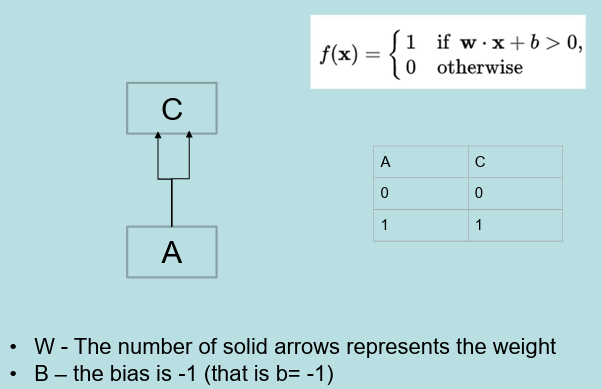



This perceptron has:

- One input node **A**
- One output node **C**
- Weight **w = 2** (represented by 2 arrows)
- Bias **b = -1**
- Activation function is a **step function**:
  
  $$
  f(x) = 
  \begin{cases} 
  1 & \text{if } w \cdot x + b > 0 \\
  0 & \text{otherwise}
  \end{cases}
  $$

Let's reproduce this in code using both **PyTorch** and **TensorFlow**.

---

## 🧪 PyTorch Implementation

Make sure to install these libraries in your virtual environment before you run the code:

```python
!pip install torch tensorflow notebook

```
```python
import torch

# Define weight and bias
w = torch.tensor(2.0)
b = torch.tensor(-1.0)

# Step activation function
def step(x):
    return 1 if x > 0 else 0

# Run for all inputs A = 0 or 1
for A in [0, 1]:
    x = torch.tensor(A, dtype=torch.float32)
    linear_output = w * x + b
    y = step(linear_output)
    print(f"Input A: {A} → Linear Output: {linear_output:.1f} → Output C: {y}")


In [27]:
import tensorflow as tf

# Define weight and bias
w = tf.constant(2.0)
b = tf.constant(-1.0)

# Step activation function
def step(x):
    return tf.where(x > 0, 1, 0)

# Run for all inputs A = 0 or 1
for A in [0, 1]:
    x = tf.constant(float(A))
    linear_output = w * x + b
    y = step(linear_output)
    print(f"Input A: {A} → Linear Output: {linear_output.numpy():.1f} → Output C: {y.numpy()}")


Input A: 0 → Linear Output: -1.0 → Output C: 0
Input A: 1 → Linear Output: 1.0 → Output C: 1


Here’s a side-by-side style comparison and integrated implementation of the Single-Layer Perceptron using both PyTorch and TensorFlow, formatted for a Jupyter Notebook. The goal is to clearly demonstrate how both frameworks approach the same logic:

In [28]:
# --- Imports ---
import torch
import tensorflow as tf

# --- Model Parameters (same for both) ---
weight = 2.0
bias = -1.0

# --- Step Activation Function (same logic) ---
def step(x):
    return 1 if x > 0 else 0

# --- Input values to test ---
inputs = [0, 1]

# --- PyTorch Implementation ---
print("🔵 PyTorch Perceptron Output")
for A in inputs:
    x_torch = torch.tensor(float(A))
    linear_output = weight * x_torch + bias
    output = step(linear_output.item())
    print(f"Input A: {A} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow Perceptron Output")
# --- TensorFlow Implementation ---
for A in inputs:
    x_tf = tf.constant(float(A))
    linear_output = weight * x_tf + bias
    output = step(linear_output.numpy())
    print(f"Input A: {A} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch Perceptron Output
Input A: 0 → Linear: -1.0 → Output C: 0
Input A: 1 → Linear: 1.0 → Output C: 1

🟢 TensorFlow Perceptron Output
Input A: 0 → Linear: -1.0 → Output C: 0
Input A: 1 → Linear: 1.0 → Output C: 1


### 🧠 AND Gate as a Perceptron: PyTorch vs TensorFlow

### Case #2 : C = A and B

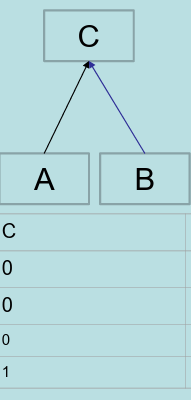

🧾 Model Description
Inputs: A, B

- Weight for A: 1
- Weight for B: 1
- Bias: -1.5

Activation: Step function (binary output)

In [29]:
import torch
import tensorflow as tf

# Shared configuration
weights = [1.0, 1.0]  # w_A = 1, w_B = 1
bias = -1.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch Perceptron Output")
for A, B in inputs:
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    linear_output = torch.dot(w, x) + bias
    output = step(linear_output.item())
    print(f"Input A={A}, B={B} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow Perceptron Output")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    linear_output = tf.reduce_sum(w * x) + bias
    output = step(linear_output.numpy())
    print(f"Input A={A}, B={B} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch Perceptron Output
Input A=0, B=0 → Linear: -1.5 → Output C: 0
Input A=1, B=0 → Linear: -0.5 → Output C: 0
Input A=0, B=1 → Linear: -0.5 → Output C: 0
Input A=1, B=1 → Linear: 0.5 → Output C: 1

🟢 TensorFlow Perceptron Output
Input A=0, B=0 → Linear: -1.5 → Output C: 0
Input A=1, B=0 → Linear: -0.5 → Output C: 0
Input A=0, B=1 → Linear: -0.5 → Output C: 0
Input A=1, B=1 → Linear: 0.5 → Output C: 1


### 🧠 OR Gate as a Perceptron: PyTorch vs TensorFlow

### Case #3 : C = A or B

🖼️ Diagram


💡 Code Walkthrough Talking Points

- Linear combination: The perceptron computes w₁·A + w₂·B + b. That’s the raw "score".
- Step activation: If the result > 0, output is 1; otherwise 0 — mimicking binary logic gates.
- Bias control: The bias -1.5 ensures that both A and B must be 1 to activate the output.

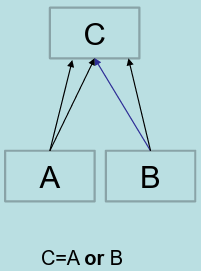

🧾 Model Description
Inputs: A, B

Weights:

- A → C: 1
- B → C: 2
- Bias: -0.5

Activation: Step function

In [30]:
import torch
import tensorflow as tf

# Model parameters
weights = [1.0, 2.0]  # A → 1, B → 2
bias = -0.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch OR Perceptron Output")
for A, B in inputs:
    # torch.tensor creates a new tensor (multi-dimensional array) from the given data.
    # Here, it converts the Python list [A, B] into a PyTorch tensor of type float32.
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    # torch.dot computes the dot product of two 1D tensors (vectors).
    # For example, torch.dot(w, x) = w[0]*x[0] + w[1]*x[1]
    linear_output = torch.dot(w, x) + bias
    output = step(linear_output.item())
    print(f"Input A={A}, B={B} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow OR Perceptron Output")
for A, B in inputs:
    # tf.constant creates a constant tensor from the given data.
    # Here, it converts the Python list [A, B] into a TensorFlow tensor of type float32.
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    linear_output = tf.reduce_sum(w * x) + bias
    output = step(linear_output.numpy())
    print(f"Input A={A}, B={B} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch OR Perceptron Output
Input A=0, B=0 → Linear: -0.5 → Output C: 0
Input A=1, B=0 → Linear: 0.5 → Output C: 1
Input A=0, B=1 → Linear: 1.5 → Output C: 1
Input A=1, B=1 → Linear: 2.5 → Output C: 1

🟢 TensorFlow OR Perceptron Output
Input A=0, B=0 → Linear: -0.5 → Output C: 0
Input A=1, B=0 → Linear: 0.5 → Output C: 1
Input A=0, B=1 → Linear: 1.5 → Output C: 1
Input A=1, B=1 → Linear: 2.5 → Output C: 1


### 💡 Code Walkthrough Talking Points
Weighting B more: Input B has a stronger influence on C (weight = 2), reflecting the blue arrow.

OR logic: With bias = -0.5, even a single active input (A or B) is enough to activate C.

Threshold control: The bias lowers the threshold so only one input needs to be active.


## 🧠 Inhibitory Logic in Perceptrons: Modeling C = A ∧ ¬B

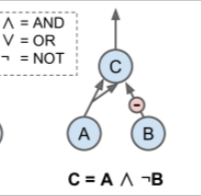

---

### 🔍 Description

- **Inputs**:
  - A (excitatory, weight = +1)
  - B (inhibitory, weight = -1)
- **Bias**: -0.5
- **Activation**: Step function

This neuron fires **only if** A is ON and B is OFF.

---


In [31]:
import torch
import tensorflow as tf

# Inputs: A, B
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]
weights = [1.0, -1.0]  # A=+1, B=-1
bias = -0.5

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch Implementation")
for A, B in inputs:
    print(f"Input A={A}, B={B}")
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    # torch.dot computes the dot product of two tensors.
    # Here, it calculates the weighted sum of inputs: z = w[0]*x + w[1]*x + bias
    z = torch.dot(w, x) + bias
    print(f"z (weighted sum) = {z.item():.1f}")
    y = step(z.item())
    print(f"A={A}, B={B} → z={z.item():.1f} → C={y}")

print("\n🟢 TensorFlow Implementation")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    z = tf.reduce_sum(w * x) + bias
    y = step(z.numpy())
    print(f"A={A}, B={B} → z={z.numpy():.1f} → C={y}")


🔵 PyTorch Implementation
Input A=0, B=0
z (weighted sum) = -0.5
A=0, B=0 → z=-0.5 → C=0
Input A=1, B=0
z (weighted sum) = 0.5
A=1, B=0 → z=0.5 → C=1
Input A=0, B=1
z (weighted sum) = -1.5
A=0, B=1 → z=-1.5 → C=0
Input A=1, B=1
z (weighted sum) = -0.5
A=1, B=1 → z=-0.5 → C=0

🟢 TensorFlow Implementation
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0



### 💬 Code Walkthrough Talking Points

- 🧲 **Inhibition as negative weight**: Neuron B has a weight of -1, which reduces the activation signal.
- 🚦 **Neuron must be off**: When B = 1, the negative weight prevents activation. This models logic gates with inhibition.
- 🧠 **Implements A AND NOT B**: This is a classic example of using simple perceptrons for logic circuits.


## 🧠 Challenge

### Use a Single Layer Perceptron to decide if you will go to the movies

Source: https://youtu.be/OFbnpY_k7js?si=aLIumFjjRtAMtxtm

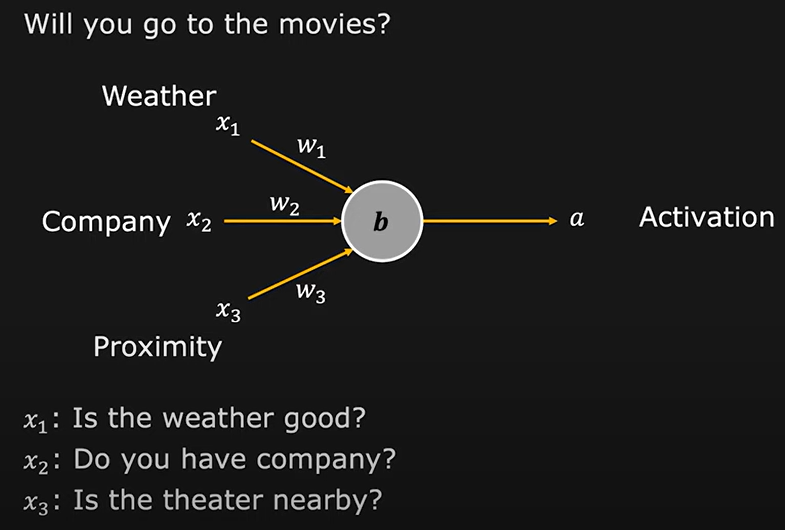

You can add and play with your own weights and biases.
Use the same activation function as in the examples above.
Add a talking point you can share with the class.

Here is a complete code cell implementing the single-layer perceptron to answer:

"Will you go to the movies?"
Based on: weather, company, and proximity

We'll use:

- Binary inputs x₁, x₂, x₃
- Weights: w₁ = 1.0 (weather), w₂ = 1.0 (company), w₃ = 1.0 (proximity)
- Bias b = -2.5 to require at least 3 "yes" answers to return a 1 (i.e., go to the movies)

In [32]:
from itertools import product

# Inputs: weather (x1), company (x2), proximity (x3)
weights = [1.0, 1.0, 1.0]   # w1, w2, w3
bias = -2.5                 # threshold: all three must be 1 for output = 1

def step(z):
    return 1 if z > 0 else 0

print("x1 x2 x3 | z      | Output")
print("----------------------------")
for x in product([0, 1], repeat=3):
    z = sum(w * xi for w, xi in zip(weights, x)) + bias
    output = step(z)
    print(f"{x[0]}  {x[1]}  {x[2]} | {z:>5.1f} |   {output}")


x1 x2 x3 | z      | Output
----------------------------
0  0  0 |  -2.5 |   0
0  0  1 |  -1.5 |   0
0  1  0 |  -1.5 |   0
0  1  1 |  -0.5 |   0
1  0  0 |  -1.5 |   0
1  0  1 |  -0.5 |   0
1  1  0 |  -0.5 |   0
1  1  1 |   0.5 |   1


🧠 Interpretation

- x₁: Is the weather good?
- x₂: Do you have company?
- x₃: Is the theater nearby?

Output 1 → You will go to the movies.

Output 0 → You won't go.

This simulates human-like logic where all conditions must be favorable.

### John's Movies Challenge — Custom Weights and Bias

I created a different decision rule using the same three inputs:

- `x1`: Good weather (1 = yes, 0 = no)
- `x2`: Have company (1 = yes, 0 = no)
- `x3`: Theater nearby (1 = yes, 0 = no)

My chosen weights are `[1.0, 2.0, 1.0]`, with a bias of `-2.5`.

I assign company a higher weight because I prefer going to the movies with someone. The perceptron calculates:

\[
z = x_1 + 2x_2 + x_3 - 2.5
\]

The step function returns 1 when \(z > 0\), and 0 otherwise.

This means I will go to the movies when I have company **and** at least one of the other two conditions is favorable.

In [33]:
from itertools import product

# John's custom Movies perceptron
# x1 = good weather, x2 = company, x3 = nearby theater
john_weights = [1.0, 2.0, 1.0]
john_bias = -2.5

def john_step(z):
    return 1 if z > 0 else 0

print("Weather Company Nearby | Score | Go to Movies")
print("-" * 49)

for x in product([0, 1], repeat=3):
    z = sum(w * xi for w, xi in zip(john_weights, x)) + john_bias
    prediction = john_step(z)
    print(f"   {x[0]}       {x[1]}       {x[2]}    | {z:5.1f} |      {prediction}")


Weather Company Nearby | Score | Go to Movies
-------------------------------------------------
   0       0       0    |  -2.5 |      0
   0       0       1    |  -1.5 |      0
   0       1       0    |  -0.5 |      0
   0       1       1    |   0.5 |      1
   1       0       0    |  -1.5 |      0
   1       0       1    |  -0.5 |      0
   1       1       0    |   0.5 |      1
   1       1       1    |   1.5 |      1


### John's Movies Challenge — Talking Point

Changing the weights and bias changes the perceptron's decision-making behavior. Unlike the original example, which required all three conditions to be favorable, my model places more importance on having company.

This demonstrates that weights control the relative importance of inputs, while the bias controls how much total evidence is required before the neuron activates.

A single-layer perceptron can represent this decision because the input combinations can be separated using a linear decision boundary.

### 🧠 How Does the Perceptron Behave as a Linear Classifier?

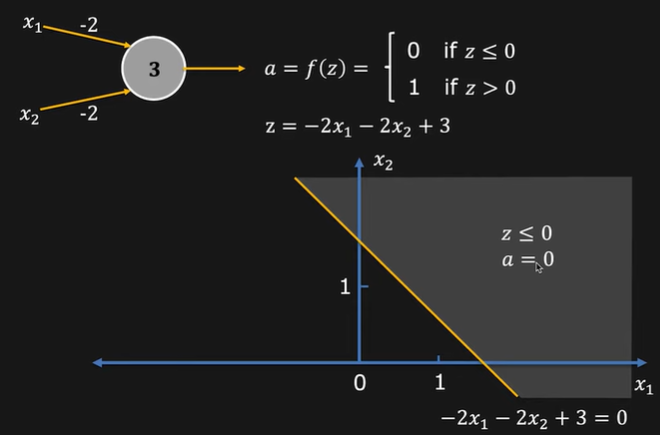

### 🧩 What's Happening in This Diagram?

- The **perceptron** computes:
  
  \[
  z = -2x_1 - 2x_2 + 3
  \]

- It then applies the **step activation**:
  
  $$
  a = 
  \begin{cases}
  1 & \text{if } z > 0 \\
  0 & \text{if } z \leq 0
  \end{cases}
  $$


### 📊 What Is the Yellow Line?

- It's the **decision boundary**, found by setting $z = 0$.
- That gives:

  $$
  -2x_1 - 2x_2 + 3 = 0 \quad \Rightarrow \quad x_2 = -x_1 + 1.5
  $$

- This line separates the input space into:

  - 🟡 **Above the line** → $z > 0$ → $a = 1$
  - ⚫ **Below or on the line** → $z \leq 0$ → $a = 0$


### 🧠 Why It Matters

This shows that a **single-layer perceptron classifies data using a straight line** (in 2D) — a **linear decision boundary**. If the inputs are linearly separable, the perceptron can perfectly classify them.


## 🧠 Challenge

Implement the Prostate Cancer prediction ANN in the Deep Learning Fundamentals class notes.

To do this:

1. Run and understand the provided Canada's Wonderland use case study and code provided with this workshop notebook.
2. Use them as a guide to implement new code and Markdown to explain it.
3. Add your Markdown, code and three talking points in the space below.

Keep the contents of the workshop and just add the new contents. 
Then copy the entire Jupyter notebook your own repository, and share the link to it for review.
Feel free to add the images folder so the notebook markdown shows the graphics it originally came with.


---
# 🩺 Challenge Solution: Prostate Cancer Prediction ANN

**Final_Project_Group 1:** Sultan Atanda · Antonio Sainz · John Buni · Echezona Oji

| Part | Topic | Slides | Author |
|---|---|---|---|
| 1 | Three-input prediction and Example 1, one patient step by step | 13–22 | Sultan Atanda |
| 2 | Example 1 on all 14 training patients | 23 | Antonio Sainz |
| 3 | Why one sigmoid neuron is not enough | 24–26 | John Buni |
| 4 | Example 2: the hidden-layer network | 27–30 | Echezona Oji |
| ✅ | Team talking points | | All |

John's Movies challenge and his answer to the Gradient Descent homework question appear earlier in the notebook, next to those sections.

## Part 1 – Example 1: One Patient, Step by Step
**Author: Sultan Atanda (9114837)**

In the Deep Learning Fundamentals class notes, the full network takes three clinical inputs and predicts one of two outcomes:

![Prostate Cancer ANN](./images/Prostate_ANN_Full.png)

- **Age** of the patient
- **PSA** (Prostate-Specific Antigen): a protein made by both normal and malignant prostate cells, measured in µg/L. Higher PSA tends to go with cancer.
- **MRI**: an imaging test that looks inside the body

We first run the **three-input prediction** for the slide 13 patient (Age = 62, PSA = 2.9, MRI = 3). Then we follow the notes' simplification to **Example 1**: a network with **no hidden layer** and **one input (PSA)** connected straight to two output nodes, **Cancer** and **Healthy**.

### 🧮 Step 0: Three-Input Prediction (Age, PSA, MRI)

Slide 13 shows one patient going into the full network:

| Input | Symbol | Value |
|---|---|---|
| Age (years) | $x_1$ | 62 |
| PSA (µg/L) | $x_2$ | 2.9 |
| MRI score | $x_3$ | 3 |

The slides do not give trained weights for this three-input network, so we use **illustrative weights** and collapse it to a **single output neuron**, exactly like the Wonderland case study:

- $w_1 = 0.03$ for Age: a small weight, because age values are large (around 60) and age is a weaker signal on its own
- $w_2 = 1.2$ for PSA: the strongest signal in the class notes
- $w_3 = 0.8$ for MRI: a higher imaging score adds suspicion
- $b = -7.0$: the bias sets how much combined evidence is needed before the neuron leans towards Cancer

$$
z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b \qquad\qquad \hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

In [34]:
import torch

x = torch.tensor([62.0, 2.9, 3.0])
weights = torch.tensor([0.03, 1.2, 0.8])
bias = -7.0

contributions = weights * x
z = contributions.sum() + bias
y_hat = torch.sigmoid(z)

for name, c in zip(["Age", "PSA", "MRI"], contributions.tolist()):
    print(f"{name:<4} w·x = {c:5.2f}")
print(f"bias      = {bias:5.2f}")
print(f"z         = {z.item():5.2f}")
print(f"P(Cancer) = {y_hat.item():.4f}  ->  {'Cancer' if y_hat.item() > 0.5 else 'Healthy'}")

Age  w·x =  1.86
PSA  w·x =  3.48
MRI  w·x =  2.40
bias      = -7.00
z         =  0.74
P(Cancer) = 0.6770  ->  Cancer


#### 📈 Interpreting the Three-Input Prediction

$$
z = (0.03 \times 62) + (1.2 \times 2.9) + (0.8 \times 3) - 7.0 = 1.86 + 3.48 + 2.40 - 7.0 = 0.74
$$

$$
\sigma(0.74) = \frac{1}{1 + e^{-0.74}} \approx 0.677
$$

- **Prediction:** 0.677 is above $\tau = 0.5$, so the neuron classifies this patient as **Cancer**, with moderate confidence.
- **Which input matters most:** PSA contributes the most (3.48), followed by MRI (2.40) and Age (1.86). The bias of −7.0 pulls the total back down, so a patient needs several warning signs at once to cross the threshold.
- **Link to the slides:** in the slide 14 training table, the patient with **PSA = 2.9 is a Cancer case**, and the trained Example 1 network gives PSA 2.9 a cancer probability of **0.902** (slide 23). Our three-input neuron agrees with both.
- **Why only one neuron?** Slide 13 draws a hidden layer, but its trained weights are not given. A single sigmoid neuron shows the same core calculation (weighted sum, bias, sigmoid, threshold). Parts 1–4 then use the **trained** weights from the slides.

### 🧾 The Trained Network (Example 1)

After training on 14 patients, the notes give these weights:

| Output node | Weight on PSA $(w_1)$ | Bias $(w_0)$ |
|---|---|---|
| Cancer | 2.747 | −5.754 |
| Healthy | −2.747 | 5.754 |

![Example 1 – PSA = 2.0](./images/Prostate_Example1.png)

We now ask the network about one new patient with **PSA = 2.0 µg/L**.

### 🔢 Step 1: Prediction Function

Each output node is a single neuron with a sigmoid activation, just like the Wonderland case:

$$
z = w_0 + \sum_{j=1}^{k} w_j x_j \qquad\qquad f(z) = \frac{1}{1 + e^{-z}}
$$

With one input, this becomes:

$$
z_{\text{cancer}} = -5.754 + 2.747 \times 2.0 \qquad\qquad z_{\text{healthy}} = 5.754 + (-2.747) \times 2.0
$$

In [35]:
import torch

class ProstateNeuron:
    def __init__(self, weight, bias, label):
        self.weight = torch.tensor(weight)
        self.bias = torch.tensor(bias)
        self.label = label

    def linear(self, psa):
        return self.bias + self.weight * psa

    def predict(self, psa):
        return torch.sigmoid(self.linear(psa))

cancer_node = ProstateNeuron(2.747, -5.754, "Cancer")
healthy_node = ProstateNeuron(-2.747, 5.754, "Healthy")

psa = torch.tensor(2.0)

for node in (cancer_node, healthy_node):
    print(f"{node.label:<8} z = {node.linear(psa).item():+.3f}   f(z) = {node.predict(psa).item():.3f}")

Cancer   z = -0.260   f(z) = 0.435
Healthy  z = +0.260   f(z) = 0.565


### 📈 Understanding the Output

- **Cancer node:** $z = -0.260$, so $f(z) \approx 0.435$
- **Healthy node:** $z = +0.260$, so $f(z) \approx 0.565$

The two outputs always add up to 1. The Healthy node is a mirror image of the Cancer node (same numbers, opposite signs), so $f(-z) = 1 - f(z)$. This is why the notes say Example 1 is **the same as logistic regression**: one sigmoid curve is enough, and the second node only reports its complement.

> 📝 **Note on the slide values:** the slides show $z = -0.251$ and $0.438$. Using the weights exactly as printed ($-5.754 + 2.747 \times 2.0$) gives $-0.260$ and $0.435$. The trained weights were most likely rounded to three decimals for the slide. The decision stays the same.

### 🚦 Applying the Threshold

To turn a probability into a diagnosis, the notes use a threshold of $\tau = 0.5$:

$$
\text{Prediction} =
\begin{cases}
\text{Cancer} & \text{if } f(z_{\text{cancer}}) > 0.5 \\
\text{Healthy} & \text{otherwise}
\end{cases}
$$

In [36]:
tau = 0.5
p_cancer = cancer_node.predict(psa).item()
p_healthy = healthy_node.predict(psa).item()

diagnosis = "Cancer" if p_cancer > tau else "Healthy"
print(f"P(Cancer) = {p_cancer:.3f}   P(Healthy) = {p_healthy:.3f}   ->   {diagnosis}")

boundary = (-cancer_node.bias / cancer_node.weight).item()
print(f"Decision boundary: PSA = {boundary:.3f} µg/L")

P(Cancer) = 0.435   P(Healthy) = 0.565   ->   Healthy
Decision boundary: PSA = 2.095 µg/L


### 🗺️ Where Does This Patient Sit on the S-Curve?

The decision boundary is where $z = 0$, which is where the sigmoid crosses 0.5:

$$
-5.754 + 2.747 \cdot \text{PSA} = 0 \;\Rightarrow\; \text{PSA} = \frac{5.754}{2.747} \approx 2.09 \ \mu g/L
$$

The chart below plots the Cancer node's curve over the 14 training patients from the notes. Our patient (PSA = 2.0) sits **just to the left** of the boundary, so the model leans Healthy, but not by much.

> Requires `plotly` (`pip install plotly`). The chart is interactive in Jupyter and VS Code. GitHub's notebook preview does not display Plotly charts.

In [37]:
import plotly.graph_objects as go

cancer_psa = [3.8, 3.4, 2.9, 2.8, 2.7, 2.1, 1.6]
healthy_psa = [2.5, 2.0, 1.7, 1.4, 1.2, 0.9, 0.8]

grid = torch.linspace(0, 5, 300)
curve = cancer_node.predict(grid)
grid, curve = grid.tolist(), curve.tolist()

fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=curve, mode="lines", name="f(z) for Cancer node",
                         line=dict(color="#C0392B", width=4)))
fig.add_trace(go.Scatter(x=cancer_psa, y=[1] * len(cancer_psa), mode="markers", name="Cancer (training)",
                         marker=dict(size=13, color="#E67E22", line=dict(width=1.5, color="white"))))
fig.add_trace(go.Scatter(x=healthy_psa, y=[0] * len(healthy_psa), mode="markers", name="Healthy (training)",
                         marker=dict(size=13, color="#27AE60", line=dict(width=1.5, color="white"))))
fig.add_trace(go.Scatter(x=[psa.item()], y=[p_cancer], mode="markers+text", name="New patient",
                         text=[f"PSA 2.0 → {p_cancer:.3f}"], textposition="middle left",
                         marker=dict(size=20, color="#2C3E50", symbol="star")))
fig.add_hline(y=tau, line=dict(dash="dot", color="grey"), annotation_text="τ = 0.5")
fig.add_vline(x=boundary, line=dict(dash="dash", color="#7F8C8D"),
              annotation_text=f"boundary ≈ {boundary:.2f}", annotation_position="top right")

fig.update_layout(title="Example 1: Probability of Prostate Cancer vs PSA",
                  xaxis_title="PSA (µg/L)", yaxis_title="P(Cancer)",
                  template="plotly_white", height=480, legend=dict(orientation="h", y=-0.2))
fig.show()

### ❌ Step 2: Error Calculation

In the training data, the patient with PSA = 2.0 is actually **Healthy**, so the true label for the Cancer node is $y = 0$.

$$
E = y - f(z) = 0 - 0.435 = -0.435
$$

The classification is correct, but the network is only 56.5% confident. The error shows there is still room to push the Cancer probability closer to 0.

In [38]:
y = torch.tensor(0.0)
error = y - cancer_node.predict(psa)
print(f"Error = {error.item():.4f}")

Error = -0.4354


### 🔁 Step 3: Weight Update with Gradient Descent

As in the Wonderland case, we use squared error loss $L = (f(z) - y)^2$ and learning rate $\eta = 0.1$. This time we update **both** the PSA weight and the bias:

$$
w_1 \leftarrow w_1 - \eta \frac{\partial L}{\partial w_1} \qquad\qquad w_0 \leftarrow w_0 - \eta \frac{\partial L}{\partial w_0}
$$

By the chain rule, $\frac{\partial L}{\partial w_1} = 2(f(z) - y)\, f(z)(1 - f(z))\, x$ and $\frac{\partial L}{\partial w_0}$ is the same without the $x$. PyTorch's autograd computes both for us.

In [39]:
w = torch.tensor(2.747, requires_grad=True)
b = torch.tensor(-5.754, requires_grad=True)
lr = 0.1

y_hat = torch.sigmoid(b + w * psa)
loss = (y_hat - y) ** 2
loss.backward()

print(f"Before: P(Cancer) = {y_hat.item():.4f}   loss = {loss.item():.4f}")
print(f"Gradients: dL/dw1 = {w.grad.item():.4f}   dL/dw0 = {b.grad.item():.4f}")

with torch.no_grad():
    w -= lr * w.grad
    b -= lr * b.grad

y_new = torch.sigmoid(b + w * psa)
print(f"Updated:  w1 = {w.item():.4f}   w0 = {b.item():.4f}")
print(f"After:  P(Cancer) = {y_new.item():.4f}   loss = {((y_new - y) ** 2).item():.4f}")

Before: P(Cancer) = 0.4354   loss = 0.1895
Gradients: dL/dw1 = 0.4281   dL/dw0 = 0.2140
Updated:  w1 = 2.7042   w0 = -5.7754
After:  P(Cancer) = 0.4093   loss = 0.1675


### 📉 What Changed?

One gradient descent step lowered the PSA weight (2.747 → 2.704) and made the bias more negative (−5.754 → −5.775). For this patient, $P(\text{Cancer})$ drops from **0.435 to 0.409** and the loss drops from **0.190 to 0.167**.

Both changes move the decision boundary to the right (from about 2.09 to about 2.14 µg/L). That pushes this healthy patient further onto the Healthy side.

⚠️ This is **one** step on **one** patient. Real training repeats this over all 14 patients many times, so that one patient doesn't pull the curve too far its own way.

### 💬 Talking Points (Sultan)

1. **Two output nodes, one decision.** The Healthy node's weights are the exact negative of the Cancer node's, so its output is always $1 - P(\text{Cancer})$. Example 1 is logistic regression drawn as a neural network. A hidden layer (Example 2) is needed before the network can learn anything a single S-curve can't.
2. **The bias sets the clinical cut-off.** The boundary $\text{PSA} = -w_0 / w_1 \approx 2.09$ µg/L is where the model switches from Healthy to Cancer. A patient at 2.0 is classed as Healthy with only 56.5% confidence. In a medical setting we might lower τ to catch more cancers, accepting more false alarms.
3. **Small rounding, visible difference.** Re-computing the slide by hand gives $z = -0.260$, not $-0.251$, because the printed weights are rounded. Coding a model is a quick way to check worked examples, and the precision of the weights matters near the boundary.

## Part 2 – Example 1 on the Full Training Set
**Author: Antonio Sainz**

**Slide 23 – "How well does this network predict the class of the training data?"**

In Part 1 we ran the Example #1 network (no hidden layer) for a single patient with PSA = 2.0.
Now we run the **same trained network on all 14 patients of the training set** and measure how many it classifies correctly.

The trained weights come from slide 19 of the *Deep Learning Fundamentals* class notes:

| Output node | Weight on PSA ($w_1$) | Bias weight ($w_0$) |
|---|---|---|
| Cancer | 2.747 | −5.754 |
| Healthy | −2.747 | +5.754 |

For every patient we compute, exactly as in the Wonderland case study:

$$
z = w_0 + w_1 \cdot \text{PSA}, \qquad f(z) = \frac{1}{1 + e^{-z}}
$$

and then apply the threshold $\tau = 0.5$: if $f(z_{\text{Cancer}}) > 0.5$ the prediction is **Cancer**, otherwise **Healthy**.
Because the Healthy node uses the same weights with the opposite sign, $f(z_{\text{Healthy}}) = 1 - f(z_{\text{Cancer}})$, so one comparison is enough.

In [40]:
import torch

# Training set from slide 23 (Status, PSA in µg/L)
status = ["Cancer"] * 7 + ["Healthy"] * 7
psa = torch.tensor([3.8, 3.4, 2.9, 2.8, 2.7, 2.1, 1.6,
                    2.5, 2.0, 1.7, 1.4, 1.2, 0.9, 0.8])

# Trained weights from slide 19 (Example #1, no hidden layer)
w_cancer, b_cancer = 2.747, -5.754
w_healthy, b_healthy = -2.747, 5.754
tau = 0.5

# Forward pass for all 14 patients at once (vectorized)
p_cancer = torch.sigmoid(w_cancer * psa + b_cancer)
p_healthy = torch.sigmoid(w_healthy * psa + b_healthy)
prediction = ["Cancer" if p > tau else "Healthy" for p in p_cancer.tolist()]

# Recreate the slide 23 table
print(f"{'Status':<8} {'PSA':>4} {'Cancer':>7} {'Healthy':>8}  {'Prediction':<10} Result")
print("-" * 52)
correct = 0
for s, x, pc, ph, pred in zip(status, psa.tolist(), p_cancer.tolist(), p_healthy.tolist(), prediction):
    ok = s == pred
    correct += ok
    print(f"{s:<8} {x:>4.1f} {pc:>7.3f} {ph:>8.3f}  {pred:<10} {'correct' if ok else 'WRONG'}")

accuracy = correct / len(status)
print("-" * 52)
print(f"Accuracy = {correct}/{len(status)} = {accuracy:.0%}")

Status    PSA  Cancer  Healthy  Prediction Result
----------------------------------------------------
Cancer    3.8   0.991    0.009  Cancer     correct
Cancer    3.4   0.973    0.027  Cancer     correct
Cancer    2.9   0.901    0.099  Cancer     correct
Cancer    2.8   0.874    0.126  Cancer     correct
Cancer    2.7   0.841    0.159  Cancer     correct
Cancer    2.1   0.504    0.496  Cancer     correct
Cancer    1.6   0.204    0.796  Healthy    WRONG
Healthy   2.5   0.753    0.247  Cancer     WRONG
Healthy   2.0   0.435    0.565  Healthy    correct
Healthy   1.7   0.253    0.747  Healthy    correct
Healthy   1.4   0.129    0.871  Healthy    correct
Healthy   1.2   0.079    0.921  Healthy    correct
Healthy   0.9   0.036    0.964  Healthy    correct
Healthy   0.8   0.028    0.972  Healthy    correct
----------------------------------------------------
Accuracy = 12/14 = 86%


### 🔍 Reading the results

- The network reproduces the slide: **12 of 14 patients are classified correctly (86%)**.
- Our probabilities differ from the slide by at most 0.003 (e.g. 0.435 vs 0.438 for PSA = 2.0). This is only rounding: the weights shown on the slides are rounded to three decimals, and slide 20 writes $z = -0.251$ where $-5.754 + 2.747 \times 2.0 = -0.260$. The predictions are identical.

**The two wrong predictions**

| Patient | Real status | Probability of cancer | Prediction | Type of error |
|---|---|---|---|---|
| PSA = 1.6 | Cancer | ≈ 0.20 | Healthy | False negative (a missed cancer) |
| PSA = 2.5 | Healthy | ≈ 0.75 | Cancer | False positive (a false alarm) |

**Why do they happen?** With only one input, the neuron can only learn **one cut point** on the PSA axis.
Setting $z = 0$ gives that boundary:

$$
-5.754 + 2.747 \cdot \text{PSA} = 0 \quad\Rightarrow\quad \text{PSA} = \frac{5.754}{2.747} \approx 2.09
$$

Everyone above 2.09 is predicted Cancer and everyone below is predicted Healthy.
The cancer patient with PSA 1.6 sits below the cut, and the healthy patient with PSA 2.5 sits above it. The two classes **overlap** between PSA 1.6 and 2.5, so no single cut point can classify all 14 patients correctly: 12/14 is the best a one-input neuron can do on this data.
The chart below shows this.

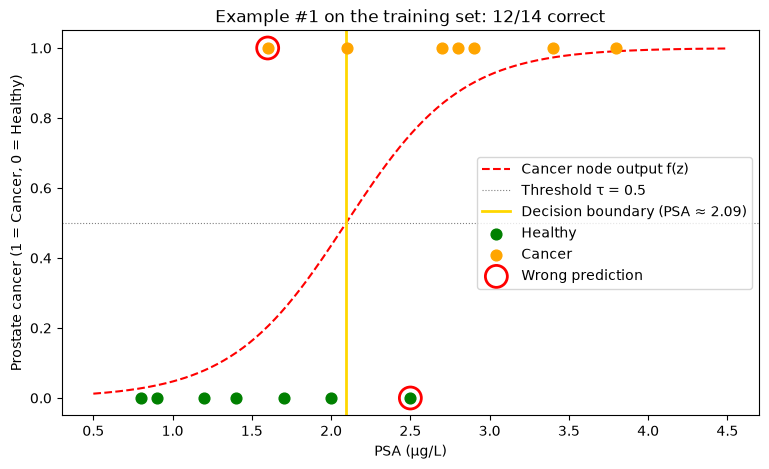

In [41]:
import matplotlib.pyplot as plt

boundary = -b_cancer / w_cancer  # PSA where z = 0, i.e. f(z) = 0.5
curve_x = torch.linspace(0.5, 4.5, 200)
curve_y = torch.sigmoid(w_cancer * curve_x + b_cancer)

is_cancer = torch.tensor([s == "Cancer" for s in status])
is_wrong = torch.tensor([s != p for s, p in zip(status, prediction)])
y_true = is_cancer.float()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve_x, curve_y, "r--", label="Cancer node output f(z)")
ax.axhline(tau, color="gray", linewidth=0.8, linestyle=":", label="Threshold τ = 0.5")
ax.axvline(boundary, color="gold", linewidth=2, label=f"Decision boundary (PSA ≈ {boundary:.2f})")
ax.scatter(psa[~is_cancer], y_true[~is_cancer], color="green", s=60, label="Healthy", zorder=3)
ax.scatter(psa[is_cancer], y_true[is_cancer], color="orange", s=60, label="Cancer", zorder=3)
ax.scatter(psa[is_wrong], y_true[is_wrong], facecolors="none", edgecolors="red", s=250,
           linewidths=2, label="Wrong prediction", zorder=4)
ax.set_xlabel("PSA (µg/L)")
ax.set_ylabel("Prostate cancer (1 = Cancer, 0 = Healthy)")
ax.set_title(f"Example #1 on the training set: {correct}/{len(status)} correct")
ax.legend(loc="center right")
plt.show()

### 💬 Antonio's insights

- **One input, one cut point.** A single neuron with one input is just a logistic regression: it turns PSA into a probability and splits patients at PSA ≈ 2.09. When the classes overlap, some errors are unavoidable, no matter how well the weights are trained.
- **Not all errors cost the same.** The PSA 1.6 patient is a *missed cancer* (false negative), which is far more dangerous than the false alarm at PSA 2.5. Lowering $\tau$ to about 0.2 would catch that patient, but it would also flag the healthy patients with PSA 1.7 and 2.0 (3 false alarms instead of 1), so in medicine the threshold is a decision, not only a math default.
- **Training accuracy is optimistic.** 86% is measured on the same 14 patients used to train the weights. To know how the network would behave with new patients we would need a separate test set, and more inputs (like Age and MRI from slide 12) to separate the overlapping cases.

## Part 3 – Why One Sigmoid Neuron Is Not Enough
**Author: John Buni**

The Deep Learning Fundamentals class notes provide 15 patients with protein levels (x) and their actual cancer status.

The data follows a non-linear classification pattern: patients with low and high protein levels have cancer, while patients with intermediate protein levels are healthy.

I will test a single sigmoid neuron with a classification threshold of 0.5, examine its predictions, and explain why one linear decision boundary cannot correctly separate all 15 patients.

Protein   Actual    Probability    Prediction  Correct
------------------------------------------------------------
3.8       Cancer    0.9991         Cancer      True
3.4       Cancer    0.9933         Cancer      True
2.9       Cancer    0.9241         Cancer      True
2.8       Cancer    0.8808         Cancer      True
2.7       Cancer    0.8176         Cancer      True
2.1       Healthy   0.1824         Healthy     True
2.0       Healthy   0.1192         Healthy     True
1.7       Healthy   0.0293         Healthy     True
1.6       Healthy   0.0180         Healthy     True
1.4       Healthy   0.0067         Healthy     True
0.9       Cancer    0.0006         Healthy     False
0.8       Cancer    0.0003         Healthy     False
0.2       Cancer    0.0000         Healthy     False
0.2       Cancer    0.0000         Healthy     False
0.1       Cancer    0.0000         Healthy     False

Accuracy: 10/15 = 66.7%

Misclassified patients:
Protein x = 0.9: Actual = Cancer, Predicted = Hea

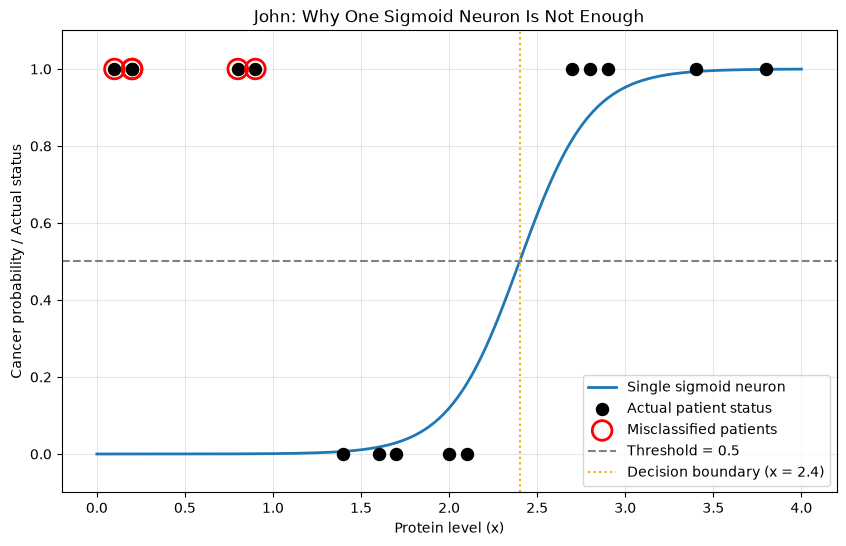

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# Actual 15 patients from the Deep Learning Fundamentals slides
protein_x = np.array([
    3.8, 3.4, 2.9, 2.8, 2.7,
    2.1, 2.0, 1.7, 1.6, 1.4,
    0.9, 0.8, 0.2, 0.2, 0.1
])

actual_status = np.array([
    "Cancer", "Cancer", "Cancer", "Cancer", "Cancer",
    "Healthy", "Healthy", "Healthy", "Healthy", "Healthy",
    "Cancer", "Cancer", "Cancer", "Cancer", "Cancer"
])

# Chosen demonstration parameters (not trained slide weights)
weight = 5.0
bias = -12.0
threshold = 0.5

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Single-neuron predictions
cancer_probability = sigmoid(weight * protein_x + bias)

predictions = np.where(
    cancer_probability >= threshold,
    "Cancer",
    "Healthy"
)

correct = predictions == actual_status
accuracy = np.mean(correct)

# Display results
print(f"{'Protein':<10}{'Actual':<10}{'Probability':<15}{'Prediction':<12}{'Correct'}")
print("-" * 60)

for x, actual, prob, pred, is_correct in zip(
    protein_x, actual_status, cancer_probability,
    predictions, correct
):
    print(f"{x:<10.1f}{actual:<10}{prob:<15.4f}{pred:<12}{is_correct}")

print(f"\nAccuracy: {np.sum(correct)}/15 = {accuracy:.1%}")

print("\nMisclassified patients:")
for x, actual, pred, is_correct in zip(
    protein_x, actual_status, predictions, correct
):
    if not is_correct:
        print(f"Protein x = {x:.1f}: Actual = {actual}, Predicted = {pred}")

# Plot sigmoid curve and actual patient labels
x_range = np.linspace(0, 4, 400)
probability_curve = sigmoid(weight * x_range + bias)
actual_numeric = np.where(actual_status == "Cancer", 1, 0)

plt.figure(figsize=(10, 6))

plt.plot(
    x_range, probability_curve,
    label="Single sigmoid neuron",
    linewidth=2
)

plt.scatter(
    protein_x, actual_numeric,
    color="black", s=75,
    label="Actual patient status",
    zorder=3
)

# Highlight incorrect predictions
plt.scatter(
    protein_x[~correct],
    actual_numeric[~correct],
    facecolors="none",
    edgecolors="red",
    s=200,
    linewidths=2,
    label="Misclassified patients",
    zorder=4
)

plt.axhline(
    threshold,
    color="gray", linestyle="--",
    label="Threshold = 0.5"
)

plt.axvline(
    -bias / weight,
    color="orange", linestyle=":",
    label="Decision boundary (x = 2.4)"
)

plt.xlabel("Protein level (x)")
plt.ylabel("Cancer probability / Actual status")
plt.title("John: Why One Sigmoid Neuron Is Not Enough")
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Interpretation and Talking Points

**Results**

Using my chosen single-neuron weights of 5.0 and bias of -12.0, the model correctly classifies 10 out of 15 patients, achieving **66.7% accuracy**.

The model correctly identifies all five high-protein cancer patients and all five healthy patients. However, it incorrectly classifies the five low-protein cancer patients (x = 0.9, 0.8, 0.2, 0.2, and 0.1) as healthy.

**Why does this happen?**

A single sigmoid neuron calculates \(z = wx + b\) and applies a sigmoid activation. Since the sigmoid is monotonic, the output can cross the 0.5 classification threshold only once when the weight is nonzero.

Our patient data requires two boundaries: one separating low-protein cancer patients from healthy patients, and another separating healthy patients from high-protein cancer patients.

Changing the weight or bias cannot solve this structural limitation. This connects to the workshop's linear decision boundary section: a single neuron can only produce a linear separation, while a network with hidden neurons can represent more complex decision patterns.

**John's Talking Points**

1. **A single neuron cannot solve every classification problem.** Even when its parameters are adjusted, it cannot correctly classify cancer at both ends of the protein range while identifying healthy patients in the middle.

2. **Accuracy does not tell the whole story.** Although the model achieves 66.7% accuracy, it misses five cancer patients. False negatives are especially important to consider in medical prediction tasks.

3. **Hidden layers increase representational power.** A network with multiple neurons can combine different decision boundaries to model non-linear relationships that a single sigmoid neuron cannot.

## Part 4 – Example 2: The Hidden-Layer Network

**Author: Echezona Oji (9078881)**

**Source:** *9C Deep Learning Fundamentals*, slides 24–30, especially the trained network and patient table on slide 27. This section implements the supplied trained weights; it does not retrain the model. All original workshop cells above are preserved.

The network has **one input → two hidden neurons → two output neurons**. The input is protein **x**, and the outputs are Cancer and Healthy. Unlike the PSA example, this data contains Cancer cases at both low and high x, with Healthy cases in the middle.

Following the Wonderland forward-pass pattern, each neuron computes a weighted sum plus bias and then applies the sigmoid:

$$\sigma(z)=\frac{1}{1+e^{-z}}.$$

| Neuron | Input weights | Bias |
|---|---|---:|
| Hidden 1 | x: 26.19 | -34.59 |
| Hidden 2 | x: 3.38 | -8.25 |
| Cancer | Hidden 1: -64.51; Hidden 2: 88.09 | 23.04 |
| Healthy | Hidden 1: 63.97; Hidden 2: -87.57 | -22.59 |

Both hidden neurons connect to both output neurons. We use **88.09 from slide 27**; the 88.009 in slide 29's worked formula is a typo. Each code cell below imports its own libraries and defines its own data and weights, so it can run independently. NumPy implements the same weighted-sum and sigmoid operations used in the Wonderland example.

$$h_1=\sigma(26.19x-34.59),\qquad h_2=\sigma(3.38x-8.25)$$
$$p_C=\sigma(-64.51h_1+88.09h_2+23.04)$$
$$p_H=\sigma(63.97h_1-87.57h_2-22.59)$$

Apply **τ = 0.5** to each output. A Cancer-only activation predicts Cancer; a Healthy-only activation predicts Healthy. Both or neither activating is explicitly flagged as ambiguous. The two sigmoid outputs are not a softmax and need not sum to exactly one.

### 4.1: Forward pass for protein x = 3 

Keep full precision during computation and round only when displaying the results.

In [43]:
import numpy as np

x = 3.0
hidden_weights = np.array([26.19, 3.38], dtype=np.float64)
hidden_biases = np.array([-34.59, -8.25], dtype=np.float64)
# Rows: Cancer, Healthy. Columns: Hidden 1, Hidden 2.
output_weights = np.array([[-64.51, 88.09], [63.97, -87.57]])
output_biases = np.array([23.04, -22.59])
tau = 0.5

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

hidden_z = hidden_weights * x + hidden_biases
hidden = sigmoid(hidden_z)
output_z = output_weights @ hidden + output_biases
probabilities = sigmoid(output_z)
active = probabilities >= tau
prediction = ("Cancer" if active[0] and not active[1] else
              "Healthy" if active[1] and not active[0] else "Ambiguous")
for i in range(2):
    print(f"Hidden {i+1}: z = {hidden_z[i]:.6f}; sigmoid = {hidden[i]:.9f}")
for i, name in enumerate(["Cancer", "Healthy"]):
    print(f"{name}: z = {output_z[i]:.6f}; sigmoid = {probabilities[i]:.12g}; active = {active[i]}")
print(f"Prediction at tau = {tau}: {prediction}")
assert np.allclose(hidden_z, [43.98, 1.89])
assert np.isclose(hidden[1], 0.869, atol=0.0005)
assert prediction == "Cancer"

Hidden 1: z = 43.980000; sigmoid = 1.000000000
Hidden 2: z = 1.890000; sigmoid = 0.868755531
Cancer: z = 35.058675; sigmoid = 1; active = True
Healthy: z = -34.696922; sigmoid = 8.5372562727e-16; active = False
Prediction at tau = 0.5: Cancer


At x = 3, the hidden pre-activations are **43.98** and **1.89**, so the hidden outputs round to **1.000** and **0.869**, matching slide 28. The output activations round to **Cancer = 1** and **Healthy = 0**, so the prediction is Cancer, matching slide 30.

These displayed zeros and ones reflect rounding or numerical saturation, rather than a step activation. The code uses sigmoid throughout. Small differences from slide 29's displayed pre-activations arise because this code keeps the unrounded hidden output and uses the corrected weight 88.09.

### 4.2: Evaluate all 15 training patients
The rows below follow slide 27 in order, including the two Cancer patients with x = 0.2. Cancer is encoded as 1 and Healthy as 0.

In [44]:
import numpy as np

# Slide 27: preserve every patient, including duplicate feature values.
x = np.array([3.8, 3.4, 2.9, 2.8, 2.7, 2.1, 2.0, 1.7,
              1.6, 1.4, 0.9, 0.8, 0.2, 0.2, 0.1], dtype=np.float64)
actual = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
hidden_weights = np.array([26.19, 3.38])
hidden_biases = np.array([-34.59, -8.25])
output_weights = np.array([[-64.51, 88.09], [63.97, -87.57]])
output_biases = np.array([23.04, -22.59])
tau = 0.5

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# Shapes: x[:, None] (15, 1), hidden (15, 2), probabilities (15, 2).
hidden = sigmoid(x[:, None] * hidden_weights + hidden_biases)
probabilities = sigmoid(hidden @ output_weights.T + output_biases)
active = probabilities >= tau
unambiguous = active.sum(axis=1) == 1
predicted = np.where(unambiguous, active[:, 0].astype(int), -1)
correct = predicted == actual
labels = {1: "Cancer", 0: "Healthy", -1: "Ambiguous"}

print(f"{'ID':>2} {'x':>4} {'Actual':<8} {'P(Cancer)':>13} {'P(Healthy)':>13} {'Prediction':<10} Correct")
print("-" * 73)
for i in range(len(x)):
    print(f"{i+1:2d} {x[i]:4.1f} {labels[actual[i]]:<8} "
          f"{probabilities[i, 0]:13.6g} {probabilities[i, 1]:13.6g} "
          f"{labels[predicted[i]]:<10} {'Yes' if correct[i] else 'No'}")
print(f"\nTraining accuracy: {correct.sum()}/{len(x)} = {correct.mean():.2%}")
print(f"Misclassified or ambiguous patient IDs: {(np.flatnonzero(~correct) + 1).tolist()}")
print("Confusion matrix (rows actual, columns predicted; order Cancer, Healthy):")
print(np.array([[np.sum((actual == a) & (predicted == p)) for p in [1, 0]]
                for a in [1, 0]]))
assert len(x) == 15 and np.sum(x == 0.2) == 2
assert unambiguous.all()
assert correct.all(), "Recheck slide 27 transcription if any patient fails."

ID    x Actual       P(Cancer)    P(Healthy) Prediction Correct
-------------------------------------------------------------------------
 1  3.8 Cancer               1   2.09253e-20 Cancer     Yes
 2  3.4 Cancer               1   2.34691e-19 Cancer     Yes
 3  2.9 Cancer               1   3.86985e-14 Cancer     Yes
 4  2.8 Cancer               1   4.45502e-12 Cancer     Yes
 5  2.7 Cancer               1   1.32246e-09 Cancer     Yes
 6  2.1 Healthy    1.50048e-09             1 Healthy    Yes
 7  2.0 Healthy    1.06195e-11             1 Healthy    Yes
 8  1.7 Healthy     7.6307e-16             1 Healthy    Yes
 9  1.6 Healthy    1.30701e-16             1 Healthy    Yes
10  1.4 Healthy    1.63772e-14             1 Healthy    Yes
11  0.9 Cancer               1    9.6105e-11 Cancer     Yes
12  0.8 Cancer               1   1.10017e-10 Cancer     Yes
13  0.2 Cancer               1    1.4783e-10 Cancer     Yes
14  0.2 Cancer               1    1.4783e-10 Cancer     Yes
15  0.1 Cancer        

**Result:** 15/15 correct, or **100% training accuracy**: all 10 Cancer cases and all 5 Healthy cases are classified correctly, with no ambiguous outputs. This reproduces the supplied training cases; it is not a held-out test or evidence of performance on unseen patients.

### 4.3: Visualize what the hidden layer adds

A sigmoid of a single affine function of x is monotonic, so thresholding it can make only one split along the x-axis. Combining two hidden sigmoids allows the Cancer output to be high at both ends and low in the middle.

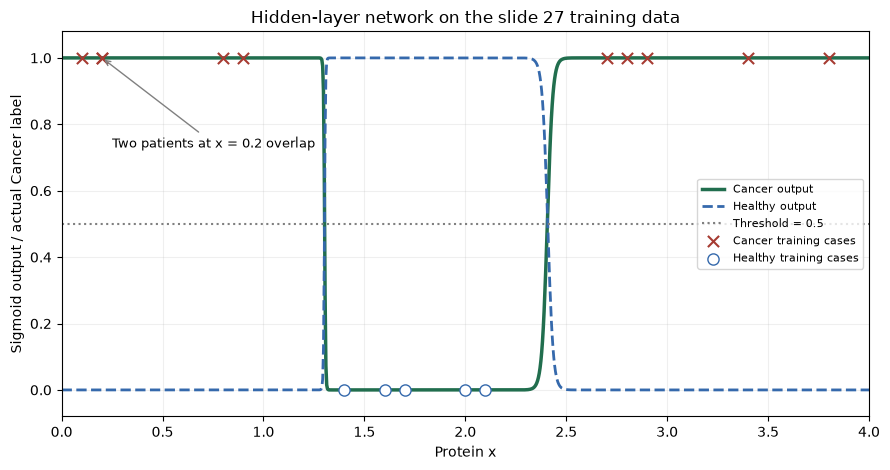

In [45]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([3.8, 3.4, 2.9, 2.8, 2.7, 2.1, 2.0, 1.7,
              1.6, 1.4, 0.9, 0.8, 0.2, 0.2, 0.1])
actual = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
hidden_weights = np.array([26.19, 3.38])
hidden_biases = np.array([-34.59, -8.25])
output_weights = np.array([[-64.51, 88.09], [63.97, -87.57]])
output_biases = np.array([23.04, -22.59])
tau = 0.5

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

grid = np.linspace(0.0, 4.0, 1000)
hidden = sigmoid(grid[:, None] * hidden_weights + hidden_biases)
probabilities = sigmoid(hidden @ output_weights.T + output_biases)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(grid, probabilities[:, 0], color="#216e4e", lw=2.5, label="Cancer output")
ax.plot(grid, probabilities[:, 1], color="#3569ac", lw=2, ls="--", label="Healthy output")
ax.axhline(tau, color="gray", ls=":", label="Threshold = 0.5")
ax.scatter(x[actual == 1], actual[actual == 1], color="#a63b32", marker="x",
           s=65, zorder=3, label="Cancer training cases")
ax.scatter(x[actual == 0], actual[actual == 0], facecolors="white", edgecolors="#3569ac",
           s=65, zorder=3, label="Healthy training cases")
ax.annotate("Two patients at x = 0.2 overlap", xy=(0.2, 1), xytext=(0.25, 0.73),
            fontsize=9, arrowprops={"arrowstyle": "->", "color": "gray"})
ax.set(xlabel="Protein x", ylabel="Sigmoid output / actual Cancer label",
       title="Hidden-layer network on the slide 27 training data",
       xlim=(0, 4), ylim=(-0.08, 1.08))
ax.legend(loc="center right", fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### 💬 Talking Points (Eche)

1. **The hidden layer changes the shape the model can represent.** Cancer occurs at low and high protein-x values, while Healthy cases lie in the middle. One monotonic sigmoid cannot isolate that middle region. Two hidden neurons give the output layer nonlinear features it can combine into the required pattern.

2. **Weights work together across layers.** Hidden 1 turns on near x = 34.59/26.19 ≈ 1.32 and inhibits the Cancer output through its -64.51 weight. Hidden 2 turns on more gradually near x = 8.25/3.38 ≈ 2.44 and pushes the Cancer output upward through its +88.09 weight. These hidden activation midpoints help explain the shape; they are not the final network's exact decision boundaries.

3. **Perfect training accuracy has a limited meaning.** The network gets all 15 supplied cases right, but those are the cases used to obtain the weights. An independent test set is needed to assess generalization. Outputs close to zero or one do not by themselves demonstrate that the model's confidence is calibrated.

---
## ✅ Team Talking Points

1. **One neuron can only make one cut.** A single sigmoid neuron is logistic regression drawn as a network. It can only split the input at one point (PSA ≈ 2.09 µg/L in Example 1). That gives 12/14 (86%) on the PSA data, where the classes overlap. On the protein-x data, where cancer appears at **both** low and high values, a single neuron misses every low-x cancer patient.

2. **A hidden layer changes the shape the model can learn.** Two hidden sigmoid neurons turn on at different protein levels (≈ 1.32 and ≈ 2.44). The output layer combines them into a "high–low–high" pattern that no single S-curve can produce. That takes the network from 66.7% to 15/15 on the Example 2 patients.

3. **In medicine, the numbers need context.** Not all errors cost the same: a missed cancer (PSA 1.6) is worse than a false alarm (PSA 2.5), so the threshold τ is a clinical decision, not just 0.5 by default. All of these accuracies are measured on the patients the weights were trained on. A separate test set, and more inputs such as Age and MRI, would be needed before trusting the model with new patients.